# classification using logistic regression


## Problem statement
+ predict wheather paitent will suffer with hearing problem

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
df = pd.read_csv('hearing_test.csv')

In [28]:
df.head()

,age,physical_score,test_result
0,33.0,40.7,1
1,50.0,37.2,1
2,52.0,24.7,0
3,56.0,31.0,0
4,35.0,42.9,1


In [3]:
df.sample(5)

,age,physical_score,test_result
4365,60.0,13.1,0
1742,56.0,36.6,1
4965,63.0,19.3,0
557,36.0,41.9,1
4310,67.0,21.0,0


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 3 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             5000 non-null   float64
 1   physical_score  5000 non-null   float64
 2   test_result     5000 non-null   int64  
dtypes: float64(2), int64(1)
memory usage: 117.3 KB


In [5]:
df.isnull().sum()

age               0
physical_score    0
test_result       0
dtype: int64

In [6]:
df.duplicated().sum()

np.int64(1470)

In [7]:
df.corr()

,age,physical_score,test_result
age,1.000000,-0.782146,-0.683171
physical_score,-0.782146,1.000000,0.792716
test_result,-0.683171,0.792716,1.000000


In [8]:
df.describe()

,age,physical_score,test_result
count,5000.000000,5000.000000,5000.000000
mean,51.609000,32.760260,0.600000
std,11.287001,8.169802,0.489947
min,18.000000,-0.000000,0.000000
25%,43.000000,26.700000,0.000000
50%,51.000000,35.300000,1.000000
75%,60.000000,38.900000,1.000000
max,90.000000,50.000000,1.000000


In [9]:
df.isna().sum()

age               0
physical_score    0
test_result       0
dtype: int64

In [10]:
df['test_result'].value_counts()

test_result
1    3000
0    2000
Name: count, dtype: int64

<BarContainer object of 2 artists>

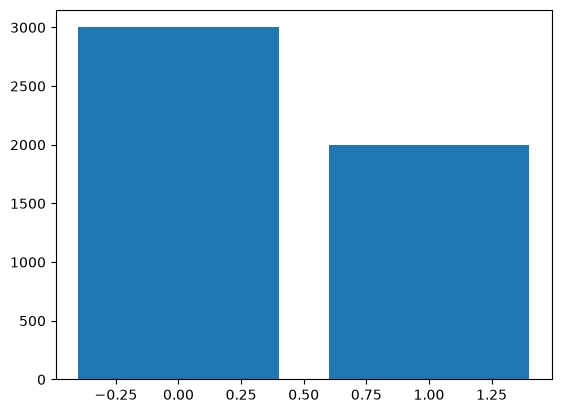

In [11]:
plt.bar(np.arange(2),df['test_result'].value_counts())

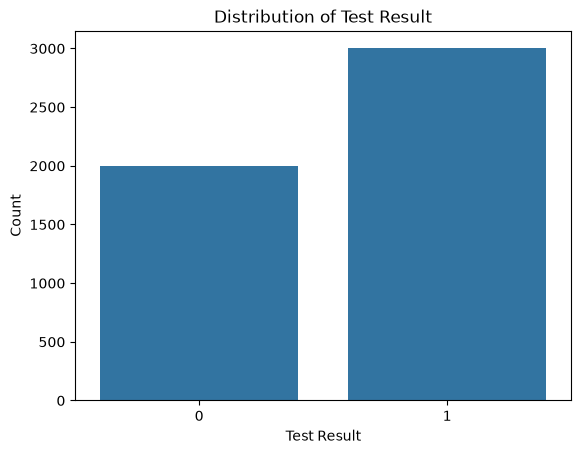

In [12]:
sns.countplot(x='test_result', data=df)

plt.xlabel("Test Result")
plt.ylabel("Count")
plt.title("Distribution of Test Result")

plt.show()

In [13]:
# splitting data
x = df.drop('test_result',axis=1)
y=df['test_result']

In [14]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(x,y,train_size=0.7,random_state=42)
# havent used stratify

In [15]:
from sklearn.linear_model import LogisticRegressionCV

model = LogisticRegressionCV()

model.fit(x_train,y_train)

d:\IT STUFF\vs code\DataScience\MACHINE_LEARNING\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:2092: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
d:\IT STUFF\vs code\DataScience\MACHINE_LEARNING\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:2137: FutureWarning: The default value of the parameter 'scoring' will change from None, i.e. accuracy, to 'neg_log_loss' in version 1.11. To silence this warning, explicitly set the scoring parameter: scoring='neg_log_loss' for the new, scoring='accuracy' or scoring=None for the old default.
  warnings.warn(
d:\IT STUFF\vs code\DataScience\MACHINE_LEARNING\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:2150: FutureWarning: The fitted attributes of LogisticRegressionCV will be 

,"Cs Cs: int or list of floats, default=10Each of the values in Cs describes the inverse of regularizationstrength. If Cs is as an int, then a grid of Cs values are chosenin a logarithmic scale between 1e-4 and 1e4.Like in support vector machines, smaller values specify strongerregularization.",10
,"l1_ratios l1_ratios: array-like of shape (n_l1_ratios), default=NoneFloats between 0 and 1 passed as Elastic-Net mixing parameter (scaling betweenL1 and L2 penalties). For `l1_ratio = 0` the penalty is an L2 penalty. For`l1_ratio = 1` it is an L1 penalty. For `0 < l1_ratio < 1`, the penalty is acombination of L1 and L2.All the values of the given array-like are tested by cross-validation and theone giving the best prediction score is used... warning:: Certain values of `l1_ratios`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... deprecated:: 1.8 `l1_ratios=None` is deprecated in 1.8 and will raise an error in version 1.10. Default value will change from `None` to `(0.0,)` in version 1.10.",'warn'
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"cv cv: int or cross-validation generator, default=NoneThe default cross-validation generator used is Stratified K-Folds.If an integer is provided, it specifies the number of folds, `n_folds`, used.See the module :mod:`sklearn.model_selection` module for thelist of possible cross-validation objects... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",None
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer dual=False whenn_samples > n_features.",False
,"penalty penalty: {'l1', 'l2', 'elasticnet'}, default='l2'Specify the norm of the penalty:- `'l2'`: add an L2 penalty term (used by default);- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"scoring scoring: str or callable, default=NoneThe scoring method to use for cross-validation. Options:- str: see :ref:`scoring_string_names` for options.- callable: a scorer callable object (e.g., function) with signature ``scorer(estimator, X, y)``. See :ref:`scoring_callable` for details.- `None`: :ref:`accuracy <accuracy_score>` is used... versionchanged:: 1.11 The default will change from None, i.e. accuracy, to 'neg_log_loss' in version 1.11.",'warn'
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' might be slo

 Training accuaracy

In [16]:
model.score(x_train,y_train)

0.9214285714285714

Test Accuracy

In [17]:
model.score(x_test,y_test)

0.9033333333333333

In [32]:
y_pred = model.predict(x_test) # can we use x test here

# plt.scatter(
#     x_train['age'][y_pred==0],
#     x_train['physical_score'][y_pred ==0],
#     color='green',
#     label= 'Will not suffer',
#     marker='s'
# )

# plt.scatter(
#     x_train['age'][y_pred==1],
#     x_train['physical_score'][y_pred==1],
#     color='red',
#     label= 'Will not suffer',
#     marker='s'
# )

# plt.xlabel("Age")
# plt.ylabel("Physical Score")
# plt.title("Classification Result")

# plt.grid(alpha=0.3)
# plt.legend()
# # plt.show()

In [29]:
print(y_pred)

[1 0 1 ... 1 1 1]


+ Remove duplicates if required
+ Stratified train-test split
+ Feature scaling
+ Confusion matrix
+ Accuracy
+ Precision
+ Recall
+ F1-score
+ Classification report
+ ROC-AUC
+ Confusion-matrix heatmap
+ Prediction probabilities
+ Test a new patient's values

Confusion matrics

In [19]:
from sklearn.metrics import confusion_matrix
cm=confusion_matrix(y_test,y_pred)
print(cm)

[[523  86]
 [ 59 832]]


Visualise confusion matrics

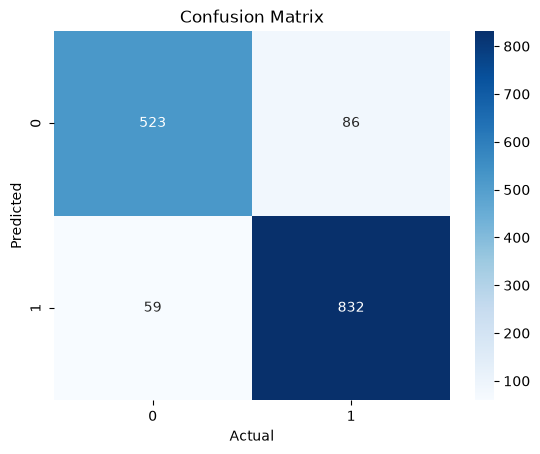

In [20]:
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.title("Confusion Matrix")

plt.show()

Classification Matrics

In [21]:
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score

In [22]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)

Accuracy : 0.9033333333333333
Precision: 0.906318082788671
Recall   : 0.9337822671156004
F1 Score : 0.9198452183526811


Classification report

In [23]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)

              precision    recall  f1-score   support

           0       0.90      0.86      0.88       609
           1       0.91      0.93      0.92       891

    accuracy                           0.90      1500
   macro avg       0.90      0.90      0.90      1500
weighted avg       0.90      0.90      0.90      1500

Accuracy : 0.9033333333333333
Precision: 0.906318082788671
Recall   : 0.9337822671156004
F1 Score : 0.9198452183526811


New Prediction

In [24]:
new_patient = pd.DataFrame({
    'age': [45],
    'physical_score': [35]
})

In [25]:
prediction=model.predict(new_patient)
print(prediction)

[1]


In [26]:
probability = model.predict_proba(new_patient)
print(probability)

[[0.12335589 0.87664411]]
